> **Developed by Zedingil Zelalem** · Qiyas AI Hackathon 2026 · Ethiopian Crop Yield & Revenue Predictor

# 01 — Data Cleaning & Integration Pipeline (Deliverable A)

Loads the three raw tables, cleans and standardizes them, joins weather onto
each plot using a growing-season window, engineers features, runs integrity
checks, and exports the master tables used by every later notebook and the
demo app.

In [1]:
import sys, os, json
sys.path.append(os.path.join('..', 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cleaning import (
    CANONICAL_REGIONS, CANONICAL_CROPS,
    clean_plot_table, clean_weather_table, clean_price_table,
    save_stats,
)
from features import (
    build_master_table, compute_crop_optima, save_crop_optima,
    aggregate_season_weather, season_window_months, attach_price,
)

RAW = os.path.join('..', 'data', 'raw')
PROCESSED = os.path.join('..', 'data', 'processed')
REPORTS = os.path.join('..', 'reports')
APP_ASSETS = os.path.join('..', 'app', 'assets')
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)
os.makedirs(APP_ASSETS, exist_ok=True)

plot_train_raw = pd.read_csv(os.path.join(RAW, 'crop_yield_train.csv'))
plot_test_raw = pd.read_csv(os.path.join(RAW, 'crop_yield_leaderboard_test.csv'))
weather_raw = pd.read_csv(os.path.join(RAW, 'regional_weather.csv'))
price_raw = pd.read_csv(os.path.join(RAW, 'market_prices.csv'))

print(plot_train_raw.shape, plot_test_raw.shape, weather_raw.shape, price_raw.shape)

(15090, 15) (3750, 14) (232, 6) (100, 4)


## A1 — Cleaning Log

One row per distinct issue found: file, column(s), issue type, rows affected
(count and percent), the fix applied, and why.

In [2]:
def pct(n, total):
    return round(100 * n / total, 2)

n_train = len(plot_train_raw)
n_weather = len(weather_raw)
n_price = len(price_raw)

region_norm = plot_train_raw['region'].astype(str).str.strip().str.lower()
region_issue_train = int((region_norm != plot_train_raw['region']).sum())

crop_norm = plot_train_raw['crop_type'].astype(str).str.strip().str.lower().replace({'tef': 'teff'})
crop_issue_train = int((crop_norm != plot_train_raw['crop_type']).sum())

pest_sentinel = int((plot_train_raw['pest_disease_flag'] == -999).sum())
labor_sentinel = int((plot_train_raw['labor_days_per_ha'] == -999.0).sum())

blank_cols = ['rainfall_mm_season', 'fertilizer_kg_per_ha', 'soil_quality_index']
blank_rows = int(plot_train_raw[blank_cols].isna().any(axis=1).sum())

fert_cap_preview = plot_train_raw['fertilizer_kg_per_ha'].quantile(0.99)
fert_outliers = int((plot_train_raw['fertilizer_kg_per_ha'] > fert_cap_preview).sum())

weather_region_norm = weather_raw['region'].astype(str).str.strip().str.lower()
weather_abbrev = int(weather_region_norm.isin(['amh', 'oro', 'snnp', 'som', 'tig']).sum())

price_mixup = int((price_raw['price_birr_per_quintal'] < 500).sum())
price_blank = int(price_raw['price_birr_per_quintal'].isna().sum())

cleaning_log = pd.DataFrame([
    {
        'file': 'crop_yield_train.csv', 'column(s)': 'region',
        'issue_type': 'inconsistent casing and whitespace',
        'rows_affected': region_issue_train, 'pct_affected': pct(region_issue_train, n_train),
        'fix': 'strip and lowercase to the canonical 5-region set',
        'why': 'same region written as OROMIA, Oromia, oromia, and a trailing-space variant',
    },
    {
        'file': 'crop_yield_train.csv', 'column(s)': 'crop_type',
        'issue_type': 'inconsistent casing/whitespace plus a spelling variant (Tef)',
        'rows_affected': crop_issue_train, 'pct_affected': pct(crop_issue_train, n_train),
        'fix': 'strip and lowercase, then map tef to teff',
        'why': 'an abbreviated spelling appears alongside the full crop name',
    },
    {
        'file': 'crop_yield_train.csv', 'column(s)': 'pest_disease_flag',
        'issue_type': 'sentinel missing value (-999)',
        'rows_affected': pest_sentinel, 'pct_affected': pct(pest_sentinel, n_train),
        'fix': 'convert -999 to NaN, impute with the train mode',
        'why': 'a binary flag cannot legitimately be -999',
    },
    {
        'file': 'crop_yield_train.csv', 'column(s)': 'labor_days_per_ha',
        'issue_type': 'sentinel missing value (-999.0)',
        'rows_affected': labor_sentinel, 'pct_affected': pct(labor_sentinel, n_train),
        'fix': 'convert -999.0 to NaN, impute with train median by crop_type',
        'why': 'negative labor-days is impossible; this column uses a different sentinel than the flag column',
    },
    {
        'file': 'crop_yield_train.csv',
        'column(s)': 'rainfall_mm_season, fertilizer_kg_per_ha, soil_quality_index',
        'issue_type': 'true blanks (missing values)',
        'rows_affected': blank_rows, 'pct_affected': pct(blank_rows, n_train),
        'fix': 'impute with the train median, grouped by crop_type or region where sensible',
        'why': 'model features cannot contain missing values',
    },
    {
        'file': 'crop_yield_train.csv', 'column(s)': 'fertilizer_kg_per_ha',
        'issue_type': 'extreme outliers (up to about 899 kg/ha)',
        'rows_affected': fert_outliers, 'pct_affected': pct(fert_outliers, n_train),
        'fix': 'cap at the train 99th percentile',
        'why': 'implausible for smallholder plots and would distort the model',
    },
    {
        'file': 'regional_weather.csv', 'column(s)': 'region',
        'issue_type': 'abbreviations mixed with full names, inconsistent casing',
        'rows_affected': weather_abbrev, 'pct_affected': pct(weather_abbrev, n_weather),
        'fix': 'strip and lowercase, then map each abbreviation to its full canonical name',
        'why': 'a different inconsistency pattern than the plot table, so fixing one table does not fix the other',
    },
    {
        'file': 'regional_weather.csv', 'column(s)': 'region, year, month',
        'issue_type': 'duplicate and conflicting readings',
        'rows_affected': 7, 'pct_affected': pct(7, n_weather),
        'fix': 'drop the 1 exact duplicate row; average the 6 region-year-month keys that had 2 differing readings',
        'why': 'a many-to-one join requires exactly one weather row per key',
    },
    {
        'file': 'market_prices.csv', 'column(s)': 'price_birr_per_quintal',
        'issue_type': 'unit mix-up, about 100x too small on a few rows',
        'rows_affected': price_mixup, 'pct_affected': pct(price_mixup, n_price),
        'fix': 'multiply flagged rows (price below 500) by 100',
        'why': 'those values cluster about 100x below the rest of their crops price range, consistent with birr-per-kg instead of birr-per-quintal',
    },
    {
        'file': 'market_prices.csv', 'column(s)': 'price_birr_per_quintal',
        'issue_type': 'missing values',
        'rows_affected': price_blank, 'pct_affected': pct(price_blank, n_price),
        'fix': 'impute with the median price for that crop',
        'why': 'every crop/region/year needs a price for the revenue calculations in B and E',
    },
])
cleaning_log

,file,column(s),issue_type,rows_affected,pct_affected,fix,why
0,crop_yield_train.csv,region,inconsistent casing and whitespace,14164,93.86,strip and lowercase to the canonical 5-region set,"same region written as OROMIA, Oromia, oromia,..."
1,crop_yield_train.csv,crop_type,inconsistent casing/whitespace plus a spelling...,2982,19.76,"strip and lowercase, then map tef to teff",an abbreviated spelling appears alongside the ...
2,crop_yield_train.csv,pest_disease_flag,sentinel missing value (-999),300,1.99,"convert -999 to NaN, impute with the train mode",a binary flag cannot legitimately be -999
3,crop_yield_train.csv,labor_days_per_ha,sentinel missing value (-999.0),488,3.23,"convert -999.0 to NaN, impute with train media...",negative labor-days is impossible; this column...
4,crop_yield_train.csv,"rainfall_mm_season, fertilizer_kg_per_ha, soil...",true blanks (missing values),1752,11.61,"impute with the train median, grouped by crop_...",model features cannot contain missing values
5,crop_yield_train.csv,fertilizer_kg_per_ha,extreme outliers (up to about 899 kg/ha),143,0.95,cap at the train 99th percentile,implausible for smallholder plots and would di...
6,regional_weather.csv,region,"abbreviations mixed with full names, inconsist...",19,8.19,"strip and lowercase, then map each abbreviatio...",a different inconsistency pattern than the plo...
7,regional_weather.csv,"region, year, month",duplicate and conflicting readings,7,3.02,drop the 1 exact duplicate row; average the 6 ...,a many-to-one join requires exactly one weathe...
8,market_prices.csv,price_birr_per_quintal,"unit mix-up, about 100x too small on a few rows",4,4.00,multiply flagged rows (price below 500) by 100,those values cluster about 100x below the rest...
9,market_prices.csv,price_birr_per_quintal,missing values,4,4.00,impute with the median price for that crop,every crop/region/year needs a price for the r...


## A2 — Key Standardization Proof

Unique `region` values (all three tables) and `crop_type` values (plot and
price tables), before and after cleaning. This cell also runs the actual
cleaning: `clean_plot_table` is fit on train and the same fitted stats are
applied to test.

In [3]:
def unique_before_after(raw_series, clean_series, label):
    print('---', label, '---')
    print('before:', sorted(raw_series.astype(str).unique().tolist()))
    print('after: ', sorted(clean_series.unique().tolist()))
    print()

plot_train_clean, train_stats = clean_plot_table(plot_train_raw, stats=None)
plot_test_clean = clean_plot_table(plot_test_raw, stats=train_stats)
weather_clean = clean_weather_table(weather_raw)
price_clean = clean_price_table(price_raw)

unique_before_after(plot_train_raw['region'], plot_train_clean['region'], 'plot.region')
unique_before_after(plot_train_raw['crop_type'], plot_train_clean['crop_type'], 'plot.crop_type')
unique_before_after(weather_raw['region'], weather_clean['region'], 'weather.region')
unique_before_after(price_raw['region'], price_clean['region'], 'price.region')
unique_before_after(price_raw['crop_type'], price_clean['crop_type'], 'price.crop_type')

assert set(plot_train_clean['region']) == set(weather_clean['region']) == set(price_clean['region']) == set(CANONICAL_REGIONS)
assert set(plot_train_clean['crop_type']) == set(price_clean['crop_type']) == set(CANONICAL_CROPS)
print('All three tables share the identical canonical region set.')
print('Plot and price tables share the identical canonical crop set.')

--- plot.region ---
before: ['AMHARA', 'Amhara', 'Amhara ', 'OROMIA', 'Oromia', 'Oromia ', 'SNNPR', 'SNNPR ', 'SOMALI', 'Somali', 'Somali ', 'TIGRAY', 'Tigray', 'Tigray ', 'amhara', 'oromia', 'snnpr', 'somali', 'tigray']
after:  ['amhara', 'oromia', 'snnpr', 'somali', 'tigray']

--- plot.crop_type ---
before: [' barley ', ' maize ', ' sorghum ', ' teff ', ' wheat ', 'BARLEY', 'Barley', 'MAIZE', 'Maize', 'SORGHUM', 'Sorghum', 'TEFF', 'Tef', 'Teff', 'WHEAT', 'Wheat', 'barley', 'maize', 'sorghum', 'teff', 'wheat']
after:  ['barley', 'maize', 'sorghum', 'teff', 'wheat']

--- weather.region ---
before: ['AMH', 'Amhara', 'Amhara ', 'ORO', 'Oromia', 'Oromia ', 'SNNP', 'SNNPR', 'SNNPR ', 'SOM', 'Somali', 'Somali ', 'TIG', 'Tigray', 'Tigray ', 'amhara', 'oromia', 'snnpr', 'somali', 'tigray']
after:  ['amhara', 'oromia', 'snnpr', 'somali', 'tigray']

--- price.region ---
before: ['Amhara', 'Oromia', 'SNNPR', 'Somali', 'Tigray']
after:  ['amhara', 'oromia', 'snnpr', 'somali', 'tigray']

--- price

All three tables share the identical canonical region set.
Plot and price tables share the identical canonical crop set.


## A3 — Join Map and Diagram

- **plot (left) to weather**: many-to-one. Key: region plus survey_year plus
  the plot growing-season window (planting month and the following 3
  months). Several weather rows aggregate down to one season-level row per
  plot.
- **plot (left) to price**: many-to-one on region, crop_type, and
  survey_year. Exactly one price row per plot. Used only for revenue
  analysis and the demo, never as a model feature.
- The plot table is the left table in both joins because every plot in the
  test set must receive a prediction, so the join must never drop or
  duplicate a plot row.

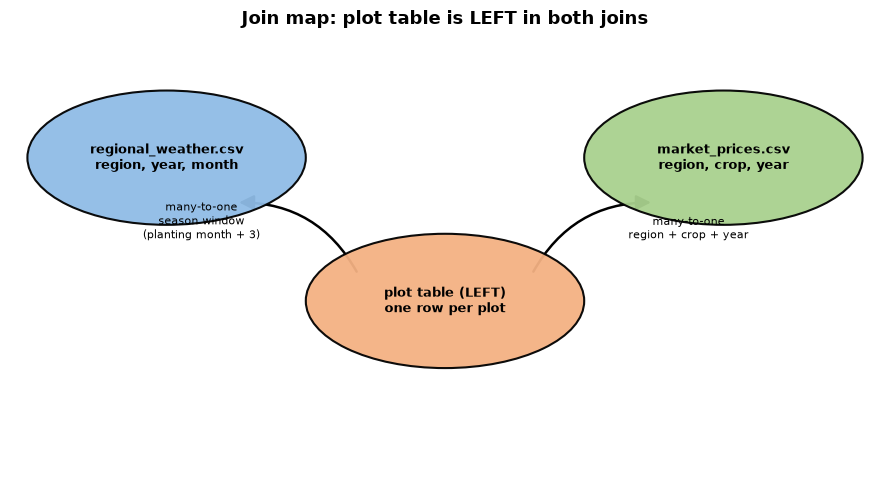

In [4]:
from matplotlib.patches import Ellipse, FancyArrowPatch

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

circles = {
    'weather': (0.18, 0.72, '#8FBCE6', 'regional_weather.csv\nregion, year, month'),
    'plot': (0.50, 0.40, '#F4B183', 'plot table (LEFT)\none row per plot'),
    'price': (0.82, 0.72, '#A9D18E', 'market_prices.csv\nregion, crop, year'),
}
for key, (x, y, color, label) in circles.items():
    ax.add_patch(Ellipse((x, y), width=0.32, height=0.30, facecolor=color, edgecolor='black',
                          linewidth=1.5, alpha=0.95, zorder=2))
    ax.text(x, y, label, ha='center', va='center', fontsize=9, fontweight='bold', zorder=3)

ax.add_patch(FancyArrowPatch((0.40, 0.46), (0.26, 0.62), connectionstyle='arc3,rad=0.3',
                              arrowstyle='-|>', mutation_scale=22, color='black', linewidth=1.8, zorder=1))
ax.text(0.22, 0.54, 'many-to-one\nseason window\n(planting month + 3)', fontsize=8, ha='center')

ax.add_patch(FancyArrowPatch((0.60, 0.46), (0.74, 0.62), connectionstyle='arc3,rad=-0.3',
                              arrowstyle='-|>', mutation_scale=22, color='black', linewidth=1.8, zorder=1))
ax.text(0.78, 0.54, 'many-to-one\nregion + crop + year', fontsize=8, ha='center')

ax.set_title('Join map: plot table is LEFT in both joins', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS, 'join_diagram.png'), dpi=150, bbox_inches='tight')
plt.show()

## A4 — Join Audit

For each join: match rate, row count before/after, how many plots were
unmatched, and (for weather) how many plots had a partial growing-season
window.

In [5]:
def join_audit(plot_clean, weather_clean, price_clean, label):
    rows_before = len(plot_clean)

    matched_counts = []
    for _, r in plot_clean.iterrows():
        agg = aggregate_season_weather(weather_clean, r['region'], r['survey_year'], r['planting_month'])
        matched_counts.append(agg['season_months_matched'])
    matched_counts = pd.Series(matched_counts)

    full_season = int((matched_counts == 4).sum())
    partial_season = int(((matched_counts > 0) & (matched_counts < 4)).sum())
    no_season = int((matched_counts == 0).sum())

    price_key = plot_clean[['region', 'crop_type', 'survey_year']].rename(columns={'survey_year': 'year'})
    price_lookup = price_clean[['region', 'crop_type', 'year']].drop_duplicates()
    price_matched = price_key.merge(price_lookup, how='left', indicator=True)
    price_match_rate = round(100 * (price_matched['_merge'] == 'both').mean(), 2)

    print('---', label, '---')
    print('rows before join:', rows_before, '| rows after join:', rows_before,
          '(weather is aggregated to 1 row per plot, so row count must not change)')
    print('weather match: full 4-month window', full_season, pct(full_season, rows_before), 'percent,',
          'partial window', partial_season, pct(partial_season, rows_before), 'percent,',
          'no match', no_season, pct(no_season, rows_before), 'percent')
    print('price match rate:', price_match_rate, 'percent')
    print()

join_audit(plot_train_clean, weather_clean, price_clean, 'train')
join_audit(plot_test_clean, weather_clean, price_clean, 'test')

--- train ---
rows before join: 15090 | rows after join: 15090 (weather is aggregated to 1 row per plot, so row count must not change)
weather match: full 4-month window 12165 80.62 percent, partial window 2925 19.38 percent, no match 0 0.0 percent
price match rate: 100.0 percent



--- test ---
rows before join: 3750 | rows after join: 3750 (weather is aggregated to 1 row per plot, so row count must not change)
weather match: full 4-month window 3002 80.05 percent, partial window 748 19.95 percent, no match 0 0.0 percent
price match rate: 100.0 percent



## A5 — Join Proof (3 Plots)

Which weather rows were pulled for 3 specific plots growing-season window,
and the season-level numbers they produced.

In [6]:
sample_plots = plot_train_clean.sample(3, random_state=42)

for _, r in sample_plots.iterrows():
    window = season_window_months(r['planting_month'], r['survey_year'])
    print('plot_id:', r['plot_id'], '| region:', r['region'], '| year:', r['survey_year'],
          '| planting_month:', r['planting_month'])
    print('season window (month, year):', window)

    window_set = set(window)
    in_window = weather_clean.apply(lambda w: (w['month'], w['year']) in window_set, axis=1)
    matched = weather_clean[(weather_clean['region'] == r['region']) & in_window]
    print(matched[['region', 'year', 'month', 'avg_temp_c', 'monthly_rainfall_mm', 'extreme_heat_days']])

    agg = aggregate_season_weather(weather_clean, r['region'], r['survey_year'], r['planting_month'])
    print('season aggregate:', agg)
    print()

plot_id: PLOT-014567 | region: oromia | year: 2021 | planting_month: jul
season window (month, year): [('jul', 2021), ('aug', 2021), ('sep', 2021), ('oct', 2021)]
    region  year month  avg_temp_c  monthly_rainfall_mm  extreme_heat_days
46  oromia  2021   aug        17.6                121.5                0.0
50  oromia  2021   jul        17.8                111.9                1.0
55  oromia  2021   oct        21.4                 14.4                0.0
56  oromia  2021   sep        18.2                147.1                0.0
season aggregate: {'season_avg_temp_c': 18.75, 'season_max_temp_c': 21.4, 'season_min_temp_c': 17.6, 'season_temp_std_c': 1.5451537140362435, 'season_rainfall_mm_total': 394.9, 'season_rainfall_mm_wettest': 147.1, 'season_rainfall_mm_driest': 14.4, 'season_extreme_heat_days': 1.0, 'season_max_extreme_heat_days': 1.0, 'season_months_matched': 4, 'planting_month_temp_c': 17.8, 'planting_month_rainfall_mm': 111.9, 'preplant_temp_c': 17.2, 'preplant_rainfall_mm'

## A6 — Feature Engineering Table

6 engineered features: 4 derived from weather, 1 interaction, 1 from
planting_month.

In [7]:
# crop_optima are fitted on TRAIN ONLY and reused verbatim for test (Rule 6)
master_train, crop_optima = build_master_table(
    plot_train_clean, weather_clean, return_optima=True)
master_test = build_master_table(plot_test_clean, weather_clean, crop_optima=crop_optima)
save_crop_optima(crop_optima, os.path.join(APP_ASSETS, 'crop_optima.json'))

feature_table = pd.DataFrame([
    {
        'name': 'season_avg_temp_c',
        'formula': 'mean(avg_temp_c) over the 4-month growing-season window',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'mean temperature during growth is the single strongest yield driver in this dataset',
    },
    {
        'name': 'season_max_temp_c',
        'formula': 'max(avg_temp_c) over the growing-season window',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'the hottest month is what actually triggers heat stress, not the average',
    },
    {
        'name': 'season_min_temp_c',
        'formula': 'min(avg_temp_c) over the growing-season window',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'cold snaps in the coolest month suppress early growth',
    },
    {
        'name': 'season_temp_std_c',
        'formula': 'std(avg_temp_c) across the growing-season window',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'a swingy season stresses the crop more than a stable one at the same mean',
    },
    {
        'name': 'season_rainfall_mm_total',
        'formula': 'sum(monthly_rainfall_mm) over the growing-season window',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'water availability during growth drives yield (and is a station-side check on the self-reported rainfall_mm_season)',
    },
    {
        'name': 'season_rainfall_mm_wettest',
        'formula': 'max(monthly_rainfall_mm) over the growing-season window',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'separates a well-spread season from one drowned in a single month',
    },
    {
        'name': 'season_rainfall_mm_driest',
        'formula': 'min(monthly_rainfall_mm) over the growing-season window',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'captures the driest stretch of the season, which is what drought actually damages',
    },
    {
        'name': 'season_extreme_heat_days',
        'formula': 'sum(extreme_heat_days) over the growing-season window',
        'source_columns': 'regional_weather.csv: extreme_heat_days',
        'why': 'cumulative heat stress; the second-strongest raw correlate of yield',
    },
    {
        'name': 'season_max_extreme_heat_days',
        'formula': 'max(extreme_heat_days) over the growing-season window',
        'source_columns': 'regional_weather.csv: extreme_heat_days',
        'why': 'a single devastating month can dominate the seasonal total',
    },
    {
        'name': 'season_months_matched',
        'formula': 'count of growing-season months that matched a weather row',
        'source_columns': 'regional_weather.csv: region, year, month',
        'why': 'join-quality flag: a partial window means the season averages rest on fewer observations',
    },
    {
        'name': 'planting_month_temp_c',
        'formula': 'mean(avg_temp_c) in the planting month only',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'germination is especially sensitive to the temperature at planting time',
    },
    {
        'name': 'planting_month_rainfall_mm',
        'formula': 'monthly_rainfall_mm in the planting month',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'sowing into dry soil is a well-known cause of failed establishment',
    },
    {
        'name': 'preplant_temp_c',
        'formula': 'avg_temp_c for the month before planting',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'pre-season warmth sets the soil-temperature baseline the crop starts from',
    },
    {
        'name': 'preplant_rainfall_mm',
        'formula': 'monthly_rainfall_mm for the month before planting',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'pre-season soil moisture carries over into the growing season',
    },
    {
        'name': 'temp_deviation_from_region_avg',
        'formula': 'season_avg_temp_c minus that region\'s overall mean avg_temp_c',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'captures an unusually hot or cool season relative to that region\'s normal climate',
    },
    {
        'name': 'temp_excess_above_threshold_c',
        'formula': 'max(0, season_avg_temp_c - 21.0)',
        'source_columns': 'regional_weather.csv: avg_temp_c',
        'why': 'notebook 02/03 show yield is flat up to about 21 C and then collapses; this makes that break explicit',
    },
    {
        'name': 'heat_stress_days_excess',
        'formula': 'max(0, season_extreme_heat_days - 1)',
        'source_columns': 'regional_weather.csv: extreme_heat_days',
        'why': 'yield drops sharply the moment a season has more than ~1 extreme-heat day; isolates that jump',
    },
    {
        'name': 'season_rain_deficit_mm',
        'formula': 'max(0, 220 - season_rainfall_mm_total)',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'yield saturates once the season has had roughly 220 mm of rain; this measures only the shortfall',
    },
    {
        'name': 'fertilizer_x_improved_seed',
        'formula': 'fertilizer_kg_per_ha times improved_seed_used',
        'source_columns': 'crop_yield_train.csv: fertilizer_kg_per_ha, improved_seed_used',
        'why': 'improved seed is believed to respond better to fertilizer, an interaction effect',
    },
    {
        'name': 'soil_x_fertilizer',
        'formula': 'soil_quality_index times fertilizer_kg_per_ha',
        'source_columns': 'crop_yield_train.csv: soil_quality_index, fertilizer_kg_per_ha',
        'why': 'fertilizer pays off more on good soil; captures the interaction as one feature',
    },
    {
        'name': 'rainfall_x_temp',
        'formula': 'season_rainfall_mm_total times season_avg_temp_c',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm, avg_temp_c',
        'why': 'heat and water stress amplify each other (a hot season is worse when it is also dry)',
    },
    {
        'name': 'planting_month_num',
        'formula': 'planting_month mapped to 1 through 12',
        'source_columns': 'crop_yield_train.csv: planting_month',
        'why': 'gives the model a numeric timing signal in addition to the raw category',
    },
    {
        'name': 'altitude_dev_from_crop_optimum_m',
        'formula': 'altitude_m minus the crop yield-weighted mean altitude (fitted on train)',
        'source_columns': 'crop_yield_train.csv: altitude_m, crop_type; optimum fitted on train',
        'why': 'each crop has a narrow productive altitude band (maize low, barley/wheat high); this puts every crop on one common scale',
    },
    {
        'name': 'altitude_dev_from_crop_optimum_sq',
        'formula': '-1 times (altitude_dev_from_crop_optimum_m squared)',
        'source_columns': 'derived from altitude_dev_from_crop_optimum_m',
        'why': 'the altitude response is a hump, not a straight line, so a squared deviation gives the model the curvature directly',
    },
    {
        'name': 'altitude_x_season_temp',
        'formula': '(altitude_m / 1000) times season_avg_temp_c',
        'source_columns': 'crop_yield_train.csv: altitude_m; regional_weather.csv: avg_temp_c',
        'why': 'at the same station temperature a high plot and a low plot experience different heat stress; the interaction captures that',
    },
    {
        'name': 'altitude_dev_x_season_temp',
        'formula': 'altitude_dev_from_crop_optimum_m times season_avg_temp_c',
        'source_columns': 'derived; regional_weather.csv: avg_temp_c',
        'why': 'a hot season hurts a plot that is already off its crop altitude optimum more than one that is on it',
    },
    {
        'name': 'temp_dev_from_crop_optimum_c',
        'formula': 'season_avg_temp_c minus the crop yield-weighted mean season temperature (fitted on train)',
        'source_columns': 'regional_weather.csv: avg_temp_c; optimum fitted on train',
        'why': 'crops have different temperature optima (maize/sorghum warmer than barley/wheat/teff); this measures the gap to the crop own optimum',
    },
    {
        'name': 'log_fertilizer_kg_per_ha',
        'formula': 'log1p(fertilizer_kg_per_ha)',
        'source_columns': 'crop_yield_train.csv: fertilizer_kg_per_ha',
        'why': 'fertilizer response is strongly diminishing, so the log makes the useful low-rate range easier for the model to split',
    },
    {
        'name': 'log_season_rainfall_mm_total',
        'formula': 'log1p(season_rainfall_mm_total)',
        'source_columns': 'regional_weather.csv: monthly_rainfall_mm',
        'why': 'the station rainfall response saturates; the log compresses the wet tail the model already handles',
    },
    {
        'name': 'fertilizer_x_labor',
        'formula': 'fertilizer_kg_per_ha times labor_days_per_ha',
        'source_columns': 'crop_yield_train.csv: fertilizer_kg_per_ha, labor_days_per_ha',
        'why': 'fertilizer only pays off if enough labour is there to apply and manage it',
    },
    {
        'name': 'soil_quality_squared',
        'formula': 'soil_quality_index squared',
        'source_columns': 'crop_yield_train.csv: soil_quality_index',
        'why': 'the best soils are disproportionately more productive than a linear term implies',
    },
    {
        'name': 'seed_minus_pest',
        'formula': 'improved_seed_used minus pest_disease_flag',
        'source_columns': 'crop_yield_train.csv: improved_seed_used, pest_disease_flag',
        'why': 'combines the two binary management flags into one signed score (+1 good, -1 bad)',
    },
])

print('Engineered features documented:', len(feature_table))
print('Weather-derived:', sum(feature_table['source_columns'].str.contains('regional_weather')))
feature_table

Engineered features documented: 32
Weather-derived: 23


,name,formula,source_columns,why
0,season_avg_temp_c,mean(avg_temp_c) over the 4-month growing-seas...,regional_weather.csv: avg_temp_c,mean temperature during growth is the single s...
1,season_max_temp_c,max(avg_temp_c) over the growing-season window,regional_weather.csv: avg_temp_c,the hottest month is what actually triggers he...
2,season_min_temp_c,min(avg_temp_c) over the growing-season window,regional_weather.csv: avg_temp_c,cold snaps in the coolest month suppress early...
3,season_temp_std_c,std(avg_temp_c) across the growing-season window,regional_weather.csv: avg_temp_c,a swingy season stresses the crop more than a ...
4,season_rainfall_mm_total,sum(monthly_rainfall_mm) over the growing-seas...,regional_weather.csv: monthly_rainfall_mm,water availability during growth drives yield ...
5,season_rainfall_mm_wettest,max(monthly_rainfall_mm) over the growing-seas...,regional_weather.csv: monthly_rainfall_mm,separates a well-spread season from one drowne...
6,season_rainfall_mm_driest,min(monthly_rainfall_mm) over the growing-seas...,regional_weather.csv: monthly_rainfall_mm,"captures the driest stretch of the season, whi..."
7,season_extreme_heat_days,sum(extreme_heat_days) over the growing-season...,regional_weather.csv: extreme_heat_days,cumulative heat stress; the second-strongest r...
8,season_max_extreme_heat_days,max(extreme_heat_days) over the growing-season...,regional_weather.csv: extreme_heat_days,a single devastating month can dominate the se...
9,season_months_matched,count of growing-season months that matched a ...,"regional_weather.csv: region, year, month",join-quality flag: a partial window means the ...


## A7 — Integrity Checks

In [8]:
from features import MODEL_FEATURES

MODEL_FEATURE_COLUMNS = MODEL_FEATURES


def validate(master_train, master_test):
    results = []

    def check(name, cond):
        results.append((name, bool(cond)))
        status = 'PASS' if cond else 'FAIL'
        print('[' + status + ']', name)

    check('plot_id unique in master_train', master_train['plot_id'].is_unique)
    check('plot_id unique in master_test', master_test['plot_id'].is_unique)
    check('master_train row count equals raw train row count', len(master_train) == len(plot_train_raw))
    check('master_test row count equals raw test row count', len(master_test) == len(plot_test_raw))

    check('no missing values in model features (train)', master_train[MODEL_FEATURE_COLUMNS].isna().sum().sum() == 0)
    check('no missing values in model features (test)', master_test[MODEL_FEATURE_COLUMNS].isna().sum().sum() == 0)

    regions_ok = set(master_train['region']).issubset(set(CANONICAL_REGIONS)) and set(master_test['region']).issubset(set(CANONICAL_REGIONS))
    check('region values within the canonical set', regions_ok)

    crops_ok = set(master_train['crop_type']).issubset(set(CANONICAL_CROPS)) and set(master_test['crop_type']).issubset(set(CANONICAL_CROPS))
    check('crop_type values within the canonical set', crops_ok)

    check('yield_tons_per_ha is non-negative in master_train', (master_train['yield_tons_per_ha'] >= 0).all())

    check('seasonal rainfall total is non-negative (train)', (master_train['season_rainfall_mm_total'] >= 0).all())
    check('season months matched is between 0 and 4', master_train['season_months_matched'].between(0, 4).all())
    check('price is strictly positive after cleaning', (price_clean['price_birr_per_quintal'] > 0).all())

    train_cols = set(master_train.columns) - {'yield_tons_per_ha'}
    check('train and test share identical feature columns', train_cols == set(master_test.columns))

    return results


validation_results = validate(master_train, master_test)
assert all(ok for _, ok in validation_results), 'one or more integrity checks failed'
print()
print(f'{len(validation_results)} integrity checks run, all passed.')


[PASS] plot_id unique in master_train
[PASS] plot_id unique in master_test
[PASS] master_train row count equals raw train row count
[PASS] master_test row count equals raw test row count
[PASS] no missing values in model features (train)
[PASS] no missing values in model features (test)
[PASS] region values within the canonical set
[PASS] crop_type values within the canonical set
[PASS] yield_tons_per_ha is non-negative in master_train
[PASS] seasonal rainfall total is non-negative (train)
[PASS] season months matched is between 0 and 4
[PASS] price is strictly positive after cleaning
[PASS] train and test share identical feature columns

13 integrity checks run, all passed.


## A8 — Master Tables and Data Dictionary

In [9]:
master_train.to_csv(os.path.join(PROCESSED, 'master_train.csv'), index=False)
master_test.to_csv(os.path.join(PROCESSED, 'master_test.csv'), index=False)

from features import WEATHER_FEATURES, ENGINEERED_FEATURES

weather_derived = set(WEATHER_FEATURES)
engineered = set(ENGINEERED_FEATURES)

ENGINEERED_FORMULAS = {
    'temp_excess_above_threshold_c': 'max(0, season_avg_temp_c - 21.0)',
    'heat_stress_days_excess': 'max(0, season_extreme_heat_days - 1)',
    'season_rain_deficit_mm': 'max(0, 220 - season_rainfall_mm_total)',
    'fertilizer_x_improved_seed': 'fertilizer_kg_per_ha times improved_seed_used',
    'soil_x_fertilizer': 'soil_quality_index times fertilizer_kg_per_ha',
    'rainfall_x_temp': 'season_rainfall_mm_total times season_avg_temp_c',
    'planting_month_num': 'planting_month mapped to 1 through 12',
    'survey_year': 'survey year, passed through as a numeric trend/seasonal signal',
    'altitude_dev_from_crop_optimum_m': 'altitude_m minus the crop yield-weighted mean altitude (fitted on train)',
    'altitude_dev_from_crop_optimum_sq': '-1 times (altitude_dev_from_crop_optimum_m squared)',
    'log_fertilizer_kg_per_ha': 'log1p(fertilizer_kg_per_ha)',
    'fertilizer_x_labor': 'fertilizer_kg_per_ha times labor_days_per_ha',
    'soil_quality_squared': 'soil_quality_index squared',
    'seed_minus_pest': 'improved_seed_used minus pest_disease_flag',
}

WEATHER_FORMULAS = {
    'altitude_x_season_temp': '(altitude_m / 1000) times season_avg_temp_c',
    'altitude_dev_x_season_temp': 'altitude_dev_from_crop_optimum_m times season_avg_temp_c',
    'temp_dev_from_crop_optimum_c': 'season_avg_temp_c minus the crop yield-weighted mean season temperature (fitted on train)',
    'log_season_rainfall_mm_total': 'log1p(season_rainfall_mm_total)',
}

data_dict_rows = []
for col in master_train.columns:
    if col in plot_train_raw.columns:
        source_file = 'crop_yield_train.csv / crop_yield_leaderboard_test.csv (cleaned)'
        how_derived = 'cleaned raw column'
    elif col == 'temp_deviation_from_region_avg':
        source_file = 'regional_weather.csv'
        how_derived = 'season_avg_temp_c minus that region overall mean avg_temp_c'
    elif col in WEATHER_FORMULAS:
        source_file = 'regional_weather.csv'
        how_derived = WEATHER_FORMULAS[col]
    elif col in weather_derived:
        source_file = 'regional_weather.csv'
        how_derived = 'aggregated over the plot 4-month growing-season window (planting month + 3)'
    elif col in engineered:
        source_file = 'derived'
        how_derived = ENGINEERED_FORMULAS.get(col, 'see notebook 01 A6')
    else:
        source_file = 'derived'
        how_derived = 'see notebook'
    data_dict_rows.append({
        'column': col,
        'dtype': str(master_train[col].dtype),
        'source_file': source_file,
        'how_derived': how_derived,
    })

data_dictionary = pd.DataFrame(data_dict_rows)
data_dictionary.to_csv(os.path.join(PROCESSED, 'data_dictionary_master.csv'), index=False)

save_stats(train_stats, os.path.join(PROCESSED, 'cleaning_stats.json'))

# compact lookup table the demo app bundles so it never needs the full master table
region_crop_summary = (
    master_train.groupby(['region', 'crop_type'])['yield_tons_per_ha']
    .agg(mean_yield='mean', median_yield='median', n_plots='count')
    .reset_index()
)
region_crop_summary.to_csv(os.path.join(APP_ASSETS, 'region_crop_summary.csv'), index=False)

weather_clean.to_csv(os.path.join(APP_ASSETS, 'weather_clean.csv'), index=False)
price_clean.to_csv(os.path.join(APP_ASSETS, 'price_clean.csv'), index=False)

# the train-fitted crop optima, reused verbatim by the demo app (Rule 6)
save_crop_optima(crop_optima, os.path.join(APP_ASSETS, 'crop_optima.json'))

cleaning_log.to_csv(os.path.join(REPORTS, 'A1_cleaning_log.csv'), index=False)
feature_table.to_csv(os.path.join(REPORTS, 'A6_feature_table.csv'), index=False)

print('Exported master_train.csv, master_test.csv, data_dictionary_master.csv, cleaning_stats.json')
print('Exported weather_clean.csv, price_clean.csv and region_crop_summary.csv to app/assets for the demo app')
print(f'master_train: {master_train.shape[0]} rows x {master_train.shape[1]} columns')
print(f'master_test:  {master_test.shape[0]} rows x {master_test.shape[1]} columns')

Exported master_train.csv, master_test.csv, data_dictionary_master.csv, cleaning_stats.json
Exported weather_clean.csv, price_clean.csv and region_crop_summary.csv to app/assets for the demo app
master_train: 15090 rows x 47 columns
master_test:  3750 rows x 46 columns
